# 05 - Cross-validated model comparison and pure premium

## Goal of this notebook, in simple terms

Notebooks 03-04 compared the models on **one** test set. One split can be lucky or unlucky
(we saw it for severity). Here we answer two questions robustly:

1. **Is the GBM really better than the GLM, or was it luck?** We repeat the comparison 5 times on
   5 different "test" portions of the *whole* portfolio (5-fold cross-validation), with every
   metric weighted by exposure (frequency) or by number of claims (severity), and test whether the
   difference is consistent across folds.
2. **What does it mean for the price?** We combine frequency and severity into a **pure premium**
   for every policy and check how well each pricing approach separates cheap and expensive
   customers in *real euros* (uncapped claim amounts).

In [1]:
import json
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from motor_pricing import PROJECT_ROOT
from motor_pricing.data import load_processed
from motor_pricing.metrics import gini_index, lift_table, double_lift_table
from motor_pricing.models import FrequencyGLM, FrequencyGBM, SeverityGLM, SeverityGBM, NullModel
from motor_pricing.validation import (cross_validate, summarise_cv, frequency_scores, severity_scores, fold_ids)
from motor_pricing.plotting import (set_style, save, plot_lorenz, plot_lift, plot_double_lift,
                                    MODEL_COLORS, SERIES, INK_2)

set_style()
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
df = load_processed()

freq_params = json.load(open(PROJECT_ROOT / "models" / "frequency_gbm_params.json"))
sev_params = json.load(open(PROJECT_ROOT / "models" / "severity_gbm_params.json"))
print("frequency GBM params:", freq_params)
print("severity GBM params :", sev_params)

frequency GBM params: {'num_leaves': 31, 'min_child_samples': 500, 'learning_rate': 0.05, 'reg_lambda': 10.0}
severity GBM params : {'num_leaves': 3, 'min_child_samples': 200, 'n_estimators': 125}


## 1. Exposure-weighted K-fold cross-validation

### Theory
**K-fold cross-validation** splits the data into $K = 5$ folds. Each fold is used once as the
validation set while the model is trained on the other 4. Every policy is therefore predicted
exactly once by a model that never saw it (*out-of-fold* predictions), and we get 5 measurements
of each metric instead of one, from which we can estimate their **variability**.

* **Stratified** folds: each fold has the same share of policies with 0, 1, 2+ claims.
* **Weighted metrics**: frequency metrics weight each policy by its exposure, severity metrics by its
  number of claims (see notebook 03, section 4.1). An unweighted metric would let a 1-month policy
  count as much as a full year.
* The models are refitted from scratch in each fold, with the settings chosen in notebooks 03-04
  (GLM factors and binning, GBM hyper-parameters).

*Caveat:* the GBM hyper-parameters were chosen on the training part of notebook 03's split, which
overlaps with these folds; strictly, a *nested* CV would be needed. The hyper-parameter search
showed the results are insensitive to these settings (differences < 0.001 in deviance), so the
optimistic bias is negligible compared with the GBM-GLM gap.

### 1.1 Frequency

In [2]:
t0 = time.time()
freq_scores, freq_oof = cross_validate(
    df,
    {"GLM": FrequencyGLM, "GBM": lambda: FrequencyGBM(**freq_params)},
    frequency_scores,
    null_factory=lambda: NullModel("Frequency", "Exposure"),
    n_splits=5,
)
print(f"done in {time.time() - t0:.0f}s")
summarise_cv(freq_scores)

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done
done in 97s


metric deviance_explained          gini        poisson_deviance         \
                     mean    std   mean    std             mean    std   
model                                                                    
GBM                0.0654 0.0015 0.3301 0.0056           0.4468 0.0010   
GLM                0.0435 0.0018 0.2821 0.0075           0.4572 0.0009   
Null               0.0000 0.0000 0.0000 0.0000           0.4781 0.0017   

metric predicted_claims / observed_claims         
                                     mean    std  
model                                             
GBM                                0.9981 0.0078  
GLM                                1.0000 0.0037  
Null                               1.0000 0.0029

In [3]:
pivot = freq_scores.pivot_table(index="fold", columns=["metric", "model"], values="value")
pivot[["poisson_deviance", "gini"]]

metric poisson_deviance                 gini              
model               GBM    GLM   Null    GBM    GLM   Null
fold                                                      
1                0.4475 0.4573 0.4791 0.3274 0.2867 0.0000
2                0.4475 0.4573 0.4786 0.3290 0.2820 0.0000
3                0.4454 0.4561 0.4755 0.3244 0.2696 0.0000
4                0.4460 0.4569 0.4773 0.3303 0.2835 0.0000
5                0.4474 0.4586 0.4797 0.3392 0.2889 0.0000

**Is the difference significant?** For each fold we compute the *paired* difference GBM - GLM
(same validation policies for both models, so fold-to-fold variation of the data cancels out)
and run a paired t-test: $t = \bar d / (s_d/\sqrt{K})$ with $K-1 = 4$ degrees of freedom.

In [4]:
def paired(scores, metric, a="GBM", b="GLM"):
    p = scores[scores["metric"] == metric].pivot(index="fold", columns="model", values="value")
    d = p[a] - p[b]
    t = d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))
    return pd.Series({"mean diff (GBM-GLM)": d.mean(), "std diff": d.std(ddof=1), "folds GBM better": int((d < 0).sum() if "deviance" in metric and "explained" not in metric else (d > 0).sum()),
                      "t": t, "p_value (two-sided)": 2 * stats.t.sf(abs(t), len(d) - 1)})

pd.DataFrame({m: paired(freq_scores, m) for m in ["poisson_deviance", "deviance_explained", "gini"]}).T

,mean diff (GBM-GLM),std diff,folds GBM better,t,p_value (two-sided)
poisson_deviance,-0.0105,0.0006,5.0000,-37.8323,0.0000
deviance_explained,0.0219,0.0013,5.0000,37.4902,0.0000
gini,0.0479,0.0051,5.0000,20.9405,0.0000


**Interpretation**

* Across the 5 folds the GBM is better **in every fold** on every metric:
  Poisson deviance 0.4468 vs 0.4572, deviance explained **6.5% vs 4.4%** (+50% relative),
  Gini **0.330 vs 0.282**.
* The fold-to-fold standard deviations are tiny (0.001 on deviance, 0.005-0.008 on Gini) compared with
  the gap. The paired differences are extremely consistent: t ≈ 38 for deviance, 21 for Gini,
  p-values < 0.0001. **The superiority of the GBM for frequency is not luck.**
* Both models are well **balanced** (total predicted / observed claims 0.998-1.000 on average).
* The cross-validated numbers agree with the single test set of notebook 03 (D² 6.1% vs 4.2%,
  Gini 0.320 vs 0.281), which confirms that notebook's conclusions.

*Note on the null model:* its Gini is exactly 0 in every fold, as it must be: a constant prediction
cannot rank anybody.

### 1.2 Severity

In [5]:
t0 = time.time()
sev_scores, sev_oof = cross_validate(
    df,
    {"GLM": lambda: SeverityGLM(["DrivAgeGLM"], ["BonusMalusGLM"]),
     "GBM": lambda: SeverityGBM(early_stopping_rounds=0, **sev_params)},
    severity_scores,
    null_factory=lambda: NullModel("AvgClaim", "ClaimNb"),
    n_splits=5,
)
print(f"done in {time.time() - t0:.0f}s")
summarise_cv(sev_scores)

fold 1/5 done


fold 2/5 done


fold 3/5 done


fold 4/5 done


fold 5/5 done
done in 2s


metric deviance_explained        gamma_deviance          gini         \
                     mean    std           mean    std   mean    std   
model                                                                  
GBM                0.0031 0.0073         1.3160 0.0725 0.0382 0.0290   
GLM                0.0038 0.0079         1.3149 0.0700 0.0376 0.0222   
Null               0.0000 0.0000         1.3202 0.0747 0.0000 0.0000   

metric predicted_cost / observed_cost         
                                 mean    std  
model                                         
GBM                            0.9893 0.0477  
GLM                            1.0014 0.0478  
Null                           1.0014 0.0480

In [6]:
pd.DataFrame({m: paired(sev_scores, m) for m in ["gamma_deviance", "deviance_explained", "gini"]}).T

,mean diff (GBM-GLM),std diff,folds GBM better,t,p_value (two-sided)
gamma_deviance,0.0011,0.0040,3.0000,0.5906,0.5865
deviance_explained,-0.0007,0.0029,3.0000,-0.5499,0.6116
gini,0.0006,0.0179,2.0000,0.0735,0.9449


**Interpretation**

* For severity the picture is the opposite: deviance explained **0.4% (GLM) vs 0.3% (GBM)**, Gini
  0.038 vs 0.038, and the fold-to-fold standard deviations (0.7-0.8 points of D², 0.02-0.03 of Gini)
  are **larger than the values themselves**.
* The paired tests give p-values of 0.59-0.94: **no detectable difference** between the two models
  (3 folds out of 5 favour the GBM, 2 the GLM).
* Both models beat the null model only marginally: on average claim cost, the rating factors
  bring very little information.

*Real-world meaning:* the price differences between customers come almost entirely from
*how often* they claim. For severity the simple 8-parameter GLM is the sensible choice: same
accuracy, full transparency.

### 1.3 Out-of-fold lift curves for frequency

Since every policy now has an out-of-fold prediction, we can draw the lift charts on the **whole
portfolio** (678k policies) instead of the 20% test set: much less noisy.

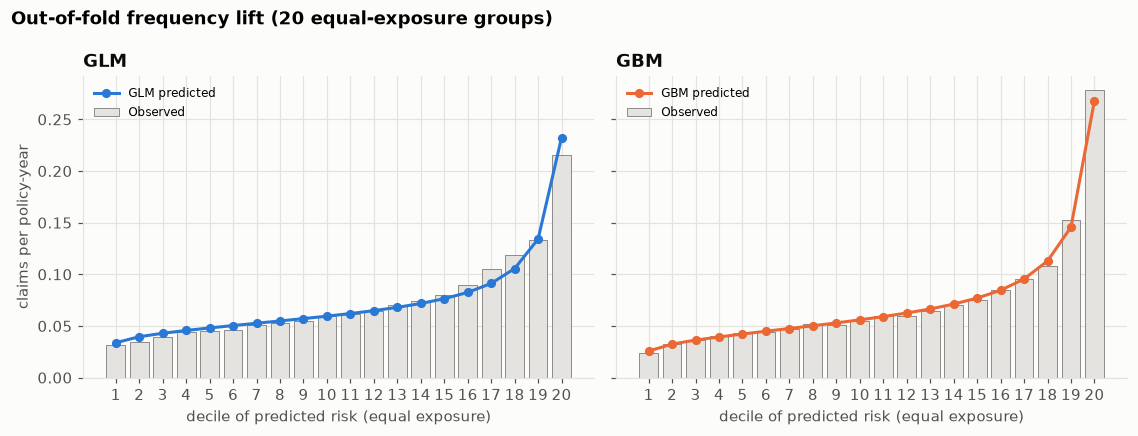

GLM                GBM         
    predicted observed predicted observed
bin                                      
1      0.0338   0.0315    0.0257   0.0239
2      0.0396   0.0347    0.0325   0.0324
10     0.0595   0.0594    0.0559   0.0552
11     0.0620   0.0612    0.0591   0.0594
18     0.1056   0.1191    0.1129   0.1084
19     0.1342   0.1337    0.1457   0.1524
20     0.2324   0.2156    0.2681   0.2781

In [7]:
y, w = df["Frequency"].to_numpy(), df["Exposure"].to_numpy()
lifts = {k: lift_table(y, freq_oof[k].to_numpy(), w, n_bins=20) for k in ["GLM", "GBM"]}
plot_lift(lifts, "Out-of-fold frequency lift (20 equal-exposure groups)", "claims per policy-year", name="05_freq_lift_oof")
pd.concat({k: v[["predicted", "observed"]] for k, v in lifts.items()}, axis=1).iloc[[0, 1, 9, 10, 17, 18, 19]]

**Interpretation** (20 groups of 5% of the exposure each)

* **Safest 5%**: GBM predicts 0.026 claims/year and observes 0.024; the GLM's safest 5% are less
  safe (0.032 observed). **Riskiest 5%**: GBM predicts 0.268 and observes **0.278**; the GLM's
  riskiest 5% observe 0.216 against a prediction of 0.232.
* The GBM therefore spreads the risk over a wider range (**~11×** between the extreme groups vs
  ~7× for the GLM) *and* stays calibrated at both ends. The GLM is too high at the bottom
  (0.034 vs 0.032) and in group 18 is too low (0.106 vs 0.119): its rigid structure cannot follow
  the data in the tails.

## 2. From frequency and severity to the pure premium

### Theory
Under the collective risk model, with the number of claims $N$ and the claim costs $X_k$
independent given the rating factors $x$:

$$\mathbb{E}\Big[\sum_{k=1}^{N} X_k \,\Big|\, x\Big] = \mathbb{E}[N\mid x]\;\mathbb{E}[X\mid x]$$

The models give, per policy-year: $\hat\lambda(x)$ (frequency) and $\hat\mu(x)$ (average *capped*
claim). The large-claim excess removed in notebook 01 is added back as a flat **large-loss
loading** $L = \frac{\sum \text{raw amounts}}{\sum \text{capped amounts}}$ estimated on the training folds:

$$\widehat{PP}(x) = \hat\lambda(x)\cdot\hat\mu(x)\cdot L \qquad \text{(EUR per policy-year)}$$

Every policy gets an out-of-fold pure premium from 3 pricing approaches:
* **GLM × GLM** - the classical actuarial tariff;
* **GBM × GBM** - full machine learning;
* **GBM × GLM** - GBM frequency with the simple severity GLM (since severity models are tied).

We evaluate against the **observed raw (uncapped) cost per policy-year**, because that is the
money the insurer actually pays.

In [8]:
folds = fold_ids(df, n_splits=5)
loading = np.empty(len(df))
for k in range(1, 6):
    tr = folds != k
    loading[folds == k] = df.loc[tr, "ClaimAmount"].sum() / df.loc[tr, "ClaimAmountCapped"].sum()
print("large-loss loading per fold:", np.round(np.unique(loading), 4))

pp = pd.DataFrame({
    "GLM x GLM": freq_oof["GLM"] * sev_oof["GLM"] * loading,
    "GBM x GBM": freq_oof["GBM"] * sev_oof["GBM"] * loading,
    "GBM x GLM": freq_oof["GBM"] * sev_oof["GLM"] * loading,
    "Null": freq_oof["Null"] * sev_oof["Null"] * loading,
}, index=df.index)
obs_pp = df["PurePremium"].to_numpy()
obs_capped = (df["ClaimAmountCapped"] / df["Exposure"]).to_numpy()

rows = {}
for name in pp:
    rows[name] = {
        "mean pure premium (EUR)": np.average(pp[name], weights=w),
        "predicted / observed total cost": np.sum(pp[name] * w) / np.sum(obs_pp * w),
        "Gini vs raw cost": gini_index(obs_pp, pp[name], w),
        "Gini vs capped cost": gini_index(obs_capped, pp[name], w),
    }
pp_summary = pd.DataFrame(rows).T
print(f"observed pure premium (raw): {np.average(obs_pp, weights=w):,.2f} EUR per policy-year")
pp_summary

large-loss loading per fold: [1.1269 1.2052 1.243  1.2446 1.256 ]


observed pure premium (raw): 167.18 EUR per policy-year


,mean pure premium (EUR),predicted / observed total cost,Gini vs raw cost,Gini vs capped cost
GLM x GLM,167.2007,1.0001,0.3840,0.3083
GBM x GBM,164.8120,0.9859,0.4110,0.3486
GBM x GLM,166.8150,0.9978,0.4133,0.3490
Null,167.1768,1.0000,-0.0852,-0.0104


**Interpretation**

* **Level.** The observed cost is €167.18 per policy-year. GLM × GLM reproduces it almost exactly
  (ratio 1.000); GBM × GBM is 1.4% low (0.986), because the Gamma GBM does not have the balance
  property (notebook 04: 0.989). In practice one would rescale the GBM premium by a single factor
  (*re-balancing*), which changes no ranking.
* **Ranking (Gini).** Against the capped cost: **0.349 (GBM × GBM) vs 0.308 (GLM × GLM)**. Against
  the raw cost: 0.411 vs 0.384. **GBM × GLM** (GBM frequency + simple severity GLM) is as good as the
  full GBM (0.349 / 0.413): the whole advantage comes from **frequency**, as expected from sections 1.1-1.2.
* The Gini against the *raw* cost is higher but noisier: it is driven by a handful of very large
  claims (see below).
* *Null row:* its pooled Gini is not exactly 0 because its constant prediction differs slightly
  between folds, so pooling the 5 folds sorts policies by fold. It is meaningless and shown only
  as a reference for the level.

In [9]:
gini_by_fold = pd.DataFrame({name: [gini_index(obs_capped[folds == k], pp[name].to_numpy()[folds == k], w[folds == k])
                                    for k in range(1, 6)] for name in ["GLM x GLM", "GBM x GBM", "GBM x GLM"]},
                            index=pd.Index(range(1, 6), name="fold"))
gini_by_fold.loc["mean"] = gini_by_fold.mean()
gini_by_fold.loc["std"] = gini_by_fold.iloc[:5].std()
gini_by_fold

,GLM x GLM,GBM x GBM,GBM x GLM
fold,,,
1,0.3573,0.3805,0.3872
2,0.3021,0.3456,0.3424
3,0.2875,0.3380,0.3347
4,0.3300,0.3682,0.3708
5,0.2708,0.3132,0.3129
mean,0.3095,0.3491,0.3496
std,0.0344,0.0264,0.0295


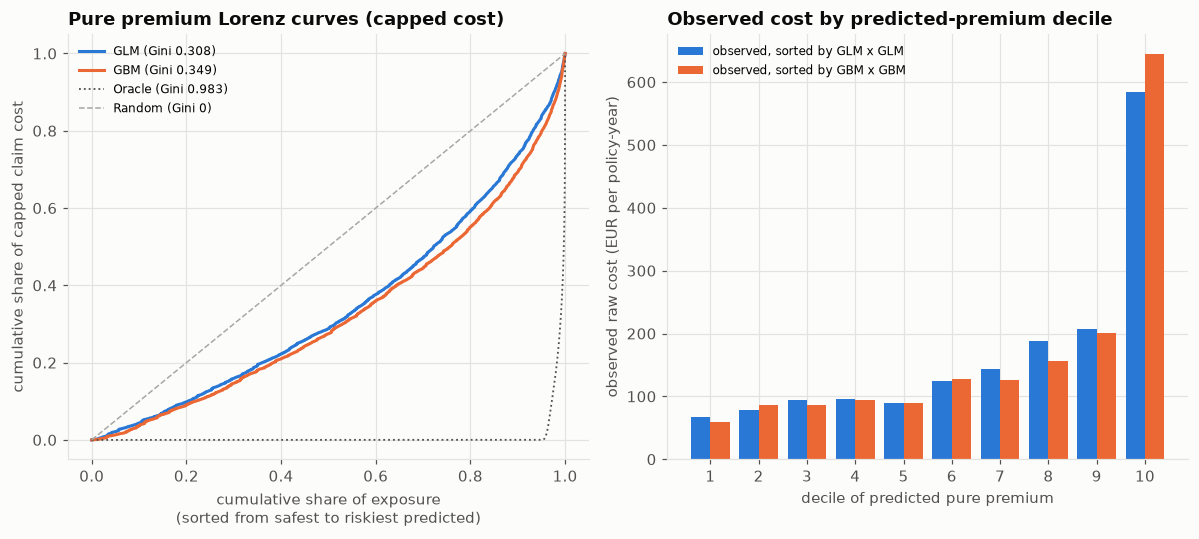

GLM x GLM          GBM x GBM         
    predicted observed predicted observed
bin                                      
1     79.5000  67.6000   62.1000  59.6000
2     96.5000  78.9000   81.9000  86.1000
3    107.4000  93.7000   94.7000  85.6000
4    117.3000  95.8000  106.5000  94.2000
5    127.4000  89.5000  118.9000  89.2000
6    138.9000 123.8000  133.3000 128.3000
7    153.7000 143.7000  152.0000 126.2000
8    176.0000 188.1000  180.5000 157.0000
9    221.9000 206.8000  235.4000 201.5000
10   453.6000 583.9000  482.8000 644.0000

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
plot_lorenz(obs_capped, {"GLM": pp["GLM x GLM"].to_numpy(), "GBM": pp["GBM x GBM"].to_numpy()}, w,
            title="Pure premium Lorenz curves (capped cost)", ax=axes[0])
axes[0].set_ylabel("cumulative share of capped claim cost")
pp_lift = {k: lift_table(obs_pp, pp[k].to_numpy(), w, n_bins=10) for k in ["GLM x GLM", "GBM x GBM"]}
x = np.arange(1, 11)
axes[1].bar(x - 0.2, pp_lift["GLM x GLM"]["observed"], width=0.4, color=MODEL_COLORS["GLM"], label="observed, sorted by GLM x GLM")
axes[1].bar(x + 0.2, pp_lift["GBM x GBM"]["observed"], width=0.4, color=MODEL_COLORS["GBM"], label="observed, sorted by GBM x GBM")
axes[1].set(xticks=x, xlabel="decile of predicted pure premium", ylabel="observed raw cost (EUR per policy-year)",
            title="Observed cost by predicted-premium decile")
axes[1].legend(fontsize=8)
plt.tight_layout(); save(fig, "05_pure_premium"); plt.show()
pd.concat({k: v[["predicted", "observed"]] for k, v in pp_lift.items()}, axis=1).round(1)

**Where do the large losses fall?** The table below splits the observed cost of each decile
(sorted by GBM x GBM) into the *capped* part, which the models are trained on, and the
*large-loss excess* above €100k, which is spread over all policies as a flat loading.

In [11]:
from motor_pricing.metrics import _weighted_bins  # same equal-exposure deciles as the lift chart
dec = pd.Series(_weighted_bins(pp["GBM x GBM"].to_numpy(), w, 10), index=df.index)
g = pd.DataFrame({"w": w, "pred": pp["GBM x GBM"] * w, "capped": obs_capped * w, "raw": obs_pp * w, "loading": loading * w}).groupby(dec.to_numpy()).sum()
big = df["ClaimAmount"] - df["ClaimAmountCapped"] > 0
print("policies with a claim above 100k per decile:", big.groupby(dec).sum().to_dict())
split = pd.DataFrame({
    "predicted": g["pred"] / g["w"],
    "predicted without loading": g["pred"] / g["loading"],
    "observed capped": g["capped"] / g["w"],
    "observed excess > 100k": (g["raw"] - g["capped"]) / g["w"],
    "observed raw": g["raw"] / g["w"],
})
split.index.name = "decile (GBM x GBM)"
split.round(1)

policies with a claim above 100k per decile: {1: 3, 2: 3, 3: 3, 4: 4, 5: 1, 6: 3, 7: 3, 8: 3, 9: 3, 10: 15}


,predicted,predicted without loading,observed capped,observed excess > 100k,observed raw
decile (GBM x GBM),,,,,
1,62.1000,51.5000,49.6000,10.0000,59.6000
2,81.9000,67.7000,75.3000,10.8000,86.1000
3,94.7000,78.2000,77.1000,8.5000,85.6000
4,106.5000,87.7000,87.3000,6.9000,94.2000
5,118.9000,97.8000,88.7000,0.6000,89.2000
6,133.3000,109.5000,117.3000,11.0000,128.3000
7,152.0000,124.7000,116.7000,9.6000,126.2000
8,180.5000,148.0000,146.5000,10.5000,157.0000
9,235.4000,193.0000,194.9000,6.6000,201.5000


**Interpretation of the pure premium charts and table**

* **Gini by fold**: GBM × GBM beats GLM × GLM in **all 5 folds** (by 0.023-0.051), so the advantage
  also holds for the final price.
* **Lift by decile**: the observed cost increases from ~€60 per policy-year in the cheapest decile
  to **~€640** in the most expensive one (GBM ranking) - a factor of ~11. With the GLM ranking the range is
  narrower (€68 to €584), and the GLM charges its cheapest decile €80 for a cost of €68 (+18%).
* **Capped part (what the models learn):** prediction without loading and observed capped cost are
  close in every decile (e.g. decile 10: €396 vs €423; decile 1: €52 vs €50). The model is
  well calibrated on the "everyday" claims.
* **Large losses:** the excess above €100k is **€221 per policy-year in decile 10**, against €1-11 in
  every other decile. **15 of the 41 claims above €100k fall in the riskiest 10% of the exposure**
  (about 4 would be expected if they were spread evenly). The flat proportional loading (×1.2)
  gives decile 10 only ~€87 of the €221 it costs.

*Mathematical meaning:* the assumption "large losses are random and proportional to the attritional
premium" is wrong in this portfolio: the probability of a catastrophic claim grows *faster* than
the premium. With only 41 large claims we cannot model this reliably, but the signal is strong.

*Real-world meaning:* the riskiest customers (young, high bonus-malus) cause both many claims and
most of the very severe bodily-injury claims. A production tariff should allocate the large-loss
loading with a separate model of large-claim *frequency* (e.g. a Poisson GLM for the count of
claims > €100k), rather than a flat factor. We record this as the main improvement to pursue.

### 2.1 What would happen in a competitive market?

**Goal:** translate the statistical difference into money with a simple thought experiment.
Suppose insurer A prices with GLM × GLM and insurer B with GBM × GBM, each charging exactly its
pure premium, and every customer buys from whoever is **cheaper**. We look at the customers each
insurer wins and at its **loss ratio** = claims paid / premiums collected (above 100% = losing money).

In [12]:
cheaper_glm = pp["GLM x GLM"] < pp["GBM x GBM"]
market = []
for label, mask, prem in [("A: GLM x GLM", cheaper_glm, pp["GLM x GLM"]), ("B: GBM x GBM", ~cheaper_glm, pp["GBM x GBM"])]:
    m = mask.to_numpy()
    market.append({"insurer": label, "share of exposure won": w[m].sum() / w.sum(),
                   "premium collected (EUR m)": np.sum(prem.to_numpy()[m] * w[m]) / 1e6,
                   "claims paid (EUR m)": np.sum(obs_pp[m] * w[m]) / 1e6,
                   "claims paid, capped (EUR m)": np.sum(obs_capped[m] * w[m]) / 1e6})
market = pd.DataFrame(market).set_index("insurer")
market["loss ratio"] = market["claims paid (EUR m)"] / market["premium collected (EUR m)"]
market["loss ratio (capped claims x loading)"] = market["claims paid, capped (EUR m)"] * loading.mean() / market["premium collected (EUR m)"]
market

,share of exposure won,premium collected (EUR m),claims paid (EUR m),"claims paid, capped (EUR m)",loss ratio,loss ratio (capped claims x loading)
insurer,,,,,,
A: GLM x GLM,0.3715,21.7520,31.9665,24.1410,1.4696,1.3486
B: GBM x GBM,0.6285,29.8717,27.9427,25.1612,0.9354,1.0235


**Interpretation**

* The GBM insurer (B) is cheaper for **63%** of the exposure and wins those customers; the GLM insurer
  (A) wins the remaining 37% - the ones the GBM considers riskier than the GLM does.
* **Loss ratio of A: 147%** (135% with capped claims + loading): for every €100 of premium it pays
  ~€135-147 in claims. **Loss ratio of B: 94%** (102% capped): roughly break-even.
* Insurer A is not unlucky: by construction it attracts precisely the customers it **under-prices**
  (the double-lift charts of notebook 03 showed where). This is **adverse selection**, and it is the
  economic reason why a better ranking (higher Gini) is worth real money.

*Caveat:* a stylised experiment (price = pure premium, customers always buy the cheaper offer,
no expenses, no retention effects). It shows the direction and order of magnitude, not a business forecast.

## 3. Conclusions

| Exposure-weighted 5-fold CV | GLM | GBM | Significant? |
|---|---|---|---|
| Frequency - Poisson deviance | 0.4572 | **0.4468** | yes, 5/5 folds, p < 0.0001 |
| Frequency - deviance explained | 4.4% | **6.5%** | yes |
| Frequency - Gini | 0.282 | **0.330** | yes, 5/5 folds |
| Severity - deviance explained | 0.4% | 0.3% | no (p ≈ 0.6) |
| Severity - Gini | 0.038 | 0.038 | no |
| Pure premium - Gini (capped cost) | 0.308 (GLM × GLM) | **0.349** (GBM × GBM) | 5/5 folds |
| Pure premium - balance | 1.000 | 0.986 (re-balance needed) | |

1. **Frequency** is where the money is: the GBM is better consistently and substantially.
2. **Severity** is barely predictable; the simple GLM is as good as the GBM.
3. The best practical combination is **GBM frequency × GLM severity** (Gini 0.349, balance 0.998).
4. In a competitive market, the GLM-priced insurer would suffer **adverse selection**
   (loss ratio ~135-147% vs ~94-102%).
5. Large losses are concentrated among the riskiest customers: a flat large-loss loading under-prices
   them - the first improvement to make.

Next: **06 - Explainability**: *why* does the GBM predict what it predicts?